In [ ]:
⁸import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
from scipy.stats import kurtosis, skew
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

train_dir = '/content/drive/MyDrive/datasets/train-emotions'
test_dir = '/content/drive/MyDrive/datasets/test-emotions'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def is_black_image(image):
    return np.max(image) == np.min(image)

def remove_black_images(folder_path):
    emotions = ['angry', 'happy']
    total_removed = 0

    for emotion in emotions:
        emotion_folder = os.path.join(folder_path, emotion)

        if not os.path.exists(emotion_folder):
            print(f"La carpeta {emotion_folder} no existe.")
            continue

        # print(f"Procesando carpeta: {emotion_folder}")

        for filename in os.listdir(emotion_folder):
            image_path = os.path.join(emotion_folder, filename)

            if filename.endswith('.jpg') or filename.endswith('.png'):
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                if is_black_image(image):
                    os.remove(image_path)
                    total_removed += 1
                    print(f"Eliminada imagen negra: {filename}")

    print(f"Total de imágenes negras eliminadas en {folder_path}: {total_removed}")

# Eliminar imágenes negras de los conjuntos train y test
remove_black_images(train_dir)
remove_black_images(test_dir)

Total de imágenes negras eliminadas en /content/drive/MyDrive/datasets/train-emotions: 0
Total de imágenes negras eliminadas en /content/drive/MyDrive/datasets/test-emotions: 0


In [ ]:

def normalize_image(image):
    min_val = np.min(image)
    max_val = np.max(image)
    if max_val - min_val == 0:
        return image  # Si la imagen es constante, devolver la misma
    else:
        return (image - min_val) / (max_val - min_val)

def calculate_statistics(image):
    mean_val = np.mean(image)
    var_val = np.var(image)
    kurt_val = kurtosis(image, axis=None)  # Curtosis sobre todos los píxeles
    skew_val = skew(image, axis=None)  # Asimetría sobre todos los píxeles
    return mean_val, var_val, kurt_val, skew_val

def preprocess_image(image):
    # Normalizar la imagen primero
    image_normalized = normalize_image(image)
    image_normalized = np.float32(image_normalized) #es necesario convertirlo a

    # Aplicar filtro bilateral para suavizado
    image_bilateral = cv2.bilateralFilter(image_normalized, 9, 75, 75)

    # Detección de bordes con Sobel (derivadas en x e y)
    sobelx = cv2.Sobel(image_normalized, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(image_normalized, cv2.CV_64F, 0, 1, ksize=5)
    image_edges = cv2.magnitude(sobelx, sobely)  # Magnitud de los bordes

    # Calcular estadísticas para ambos filtros
    bilateral_stats = calculate_statistics(image_bilateral)
    sobel_stats = calculate_statistics(image_edges)

    # Retornar todas las estadísticas como características
    features = np.hstack((bilateral_stats, sobel_stats))  # Concatenar todas las características
    return features

# Función para preprocesar las imágenes de una carpeta (50)
#def preprocess_images_in_folder(folder_path, max_images_per_folder=50):
#    features = []
#    labels = []
#
#    # Definir las etiquetas para las carpetas
#    emotion_folders = {'angry': 0, 'happy': 1}
#
#    # Recorrer las carpetas de emociones
#    for emotion, label in emotion_folders.items():
#        emotion_folder = os.path.join(folder_path, emotion)
#
#        print(f"Procesando carpeta: {emotion_folder}")
#        if not os.path.exists(emotion_folder):
#            print(f"Carpeta {emotion_folder} no encontrada")
#            continue
#
#       count = 0
#       for filename in os.listdir(emotion_folder):
#           if filename.endswith('.jpg'):
#               image_path = os.path.join(emotion_folder, filename)
#               image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
#
#               # Aplicar preprocesamiento y obtener características
#               image_features = preprocess_image(image)
#
#                features.append(image_features)
#                labels.append(label)
#
#                count += 1
#
#                # Detenerse después de procesar el número máximo de imágenes
#                if count >= max_images_per_folder:
#                    break
#
#        print(f"Total de imágenes procesadas para {emotion}: {count}")
#
#    return features, labels

# # Procesar imágenes de entrenamiento y prueba
# train_features, train_labels = preprocess_images_in_folder(train_dir)
# test_features, test_labels = preprocess_images_in_folder(test_dir)

# print("\n")
# print(f"Número de imágenes procesadas en train: {len(train_features)}")
# print(f"Número de imágenes procesadas en test: {len(test_features)}")

In [ ]:
# Función para preprocesar las imágenes de una carpeta (completo)
def preprocess_images_in_folder(folder_path):
    features = []
    labels = []

    # Definir las etiquetas para las carpetas
    emotion_folders = {'angry': 0, 'happy': 1}

    # Recorrer las carpetas de emociones
    for emotion, label in emotion_folders.items():
        emotion_folder = os.path.join(folder_path, emotion)

        print(f"Procesando carpeta: {emotion_folder}")
        if not os.path.exists(emotion_folder):
            print(f"Carpeta {emotion_folder} no encontrada")
            continue

        count = 0
        for filename in os.listdir(emotion_folder):
            if filename.endswith('.jpg'):
                image_path = os.path.join(emotion_folder, filename)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

                # Aplicar preprocesamiento y obtener características
                image_features = preprocess_image(image)

                features.append(image_features)
                labels.append(label)

                count += 1

        print(f"Total de imágenes procesadas para {emotion}: {count}")

    return features, labels

# Procesar imágenes de entrenamiento y prueba
train_features, train_labels = preprocess_images_in_folder(train_dir)
test_features, test_labels = preprocess_images_in_folder(test_dir)

Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/angry
Total de imágenes procesadas para angry: 3480
Procesando carpeta: /content/drive/MyDrive/datasets/train-emotions/happy
Total de imágenes procesadas para happy: 7214
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/angry
Total de imágenes procesadas para angry: 957
Procesando carpeta: /content/drive/MyDrive/datasets/test-emotions/happy
Total de imágenes procesadas para happy: 1774


# Sin balance

=== SVM ===
Precisión: 0.65
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.00      0.00      0.00       957
       happy       0.65      1.00      0.79      1774

    accuracy                           0.65      2731
   macro avg       0.32      0.50      0.39      2731
weighted avg       0.42      0.65      0.51      2731

=== KNN ===
Precisión: 0.63
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.46      0.31      0.37       957
       happy       0.68      0.80      0.74      1774

    accuracy                           0.63      2731
   macro avg       0.57      0.56      0.55      2731
weighted avg       0.61      0.63      0.61      2731



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


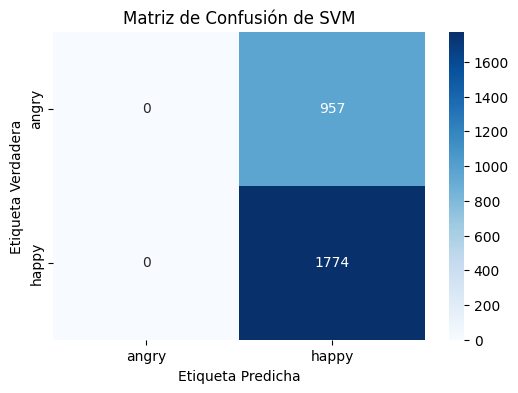

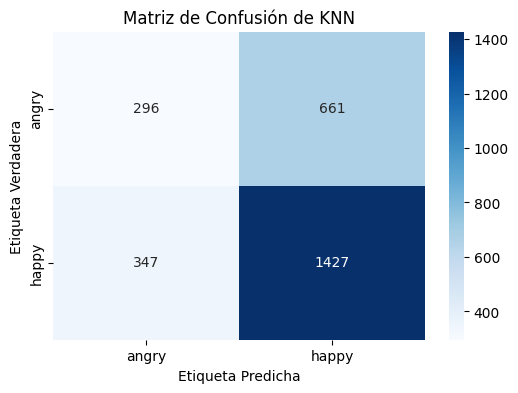

=== Validación Cruzada ===
Precisión de SVM con Validación Cruzada: 0.67 ± 0.00
Precisión de KNN con Validación Cruzada: 0.64 ± 0.01
=== Métricas Adicionales ===
SVM - Precisión: 0.65, Recall: 1.00, F1-Score: 0.79
KNN - Precisión: 0.68, Recall: 0.80, F1-Score: 0.74


In [ ]:
# Convertir a arrays de NumPy
train_features = np.array(train_features)
train_labels = np.array(train_labels)
test_features = np.array(test_features)
test_labels = np.array(test_labels)

# Escalado de características
all_features = np.vstack((train_features, test_features))
scaler = StandardScaler()
scaler.fit(all_features)

train_features_scaled = scaler.transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Entrenar y evaluar SVM
svm_classifier = SVC(kernel='linear', probability=True, random_state=42)
svm_classifier.fit(train_features_scaled, train_labels)
svm_predictions = svm_classifier.predict(test_features_scaled)

# Entrenar y evaluar KNN
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_scaled, train_labels)
knn_predictions = knn_classifier.predict(test_features_scaled)

# Evaluación de SVM
print("=== SVM ===")
svm_accuracy = accuracy_score(test_labels, svm_predictions)
print(f"Precisión: {svm_accuracy:.2f}")
svm_conf_matrix = confusion_matrix(test_labels, svm_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, svm_predictions, target_names=['angry', 'happy']))

# Evaluación de KNN
print("=== KNN ===")
knn_accuracy = accuracy_score(test_labels, knn_predictions)
print(f"Precisión: {knn_accuracy:.2f}")
knn_conf_matrix = confusion_matrix(test_labels, knn_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, knn_predictions, target_names=['angry', 'happy']))

# Visualización de las Matrices de Confusión
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")
plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

# Validación Cruzada
print("=== Validación Cruzada ===")
svm_cv_scores = cross_val_score(svm_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de SVM con Validación Cruzada: {svm_cv_scores.mean():.2f} ± {svm_cv_scores.std():.2f}")

knn_cv_scores = cross_val_score(knn_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de KNN con Validación Cruzada: {knn_cv_scores.mean():.2f} ± {knn_cv_scores.std():.2f}")

# Informe adicional de precisión, recall y F1-Score
print("=== Métricas Adicionales ===")
# SVM
svm_precision = precision_score(test_labels, svm_predictions, average='binary')
svm_recall = recall_score(test_labels, svm_predictions, average='binary')
svm_f1 = f1_score(test_labels, svm_predictions, average='binary')
print(f"SVM - Precisión: {svm_precision:.2f}, Recall: {svm_recall:.2f}, F1-Score: {svm_f1:.2f}")

# KNN
knn_precision = precision_score(test_labels, knn_predictions, average='binary')
knn_recall = recall_score(test_labels, knn_predictions, average='binary')
knn_f1 = f1_score(test_labels, knn_predictions, average='binary')
print(f"KNN - Precisión: {knn_precision:.2f}, Recall: {knn_recall:.2f}, F1-Score: {knn_f1:.2f}")

# Ajuste de Hiperparámetros
# SVM
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid, cv=5, scoring='accuracy')
svm_grid.fit(train_features_scaled, train_labels)
print(f"Mejores parámetros para SVM: {svm_grid.best_params_}")
print(f"Mejor precisión de SVM: {svm_grid.best_score_:.2f}")
best_svm = svm_grid.best_estimator_
svm_best_predictions = best_svm.predict(test_features_scaled)
print(f"Precisión del mejor SVM: {accuracy_score(test_labels, svm_best_predictions):.2f}")

# KNN
knn_param_grid = {
    'n_neighbors': list(range(1, 31)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5, scoring='accuracy')
knn_grid.fit(train_features_scaled, train_labels)
print(f"Mejores parámetros para KNN: {knn_grid.best_params_}")
print(f"Mejor precisión de KNN: {knn_grid.best_score_:.2f}")
best_knn = knn_grid.best_estimator_
knn_best_predictions = best_knn.predict(test_features_scaled)
print(f"Precisión del mejor KNN: {accuracy_score(test_labels, knn_best_predictions):.2f}")

# Con balance para SVM

=== SVM ===
Precisión: 0.61
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.44      0.39      0.41       957
       happy       0.69      0.72      0.71      1774

    accuracy                           0.61      2731
   macro avg       0.56      0.56      0.56      2731
weighted avg       0.60      0.61      0.60      2731

=== KNN ===
Precisión: 0.63
Informe de Clasificación:
              precision    recall  f1-score   support

       angry       0.46      0.31      0.37       957
       happy       0.68      0.80      0.74      1774

    accuracy                           0.63      2731
   macro avg       0.57      0.56      0.55      2731
weighted avg       0.61      0.63      0.61      2731



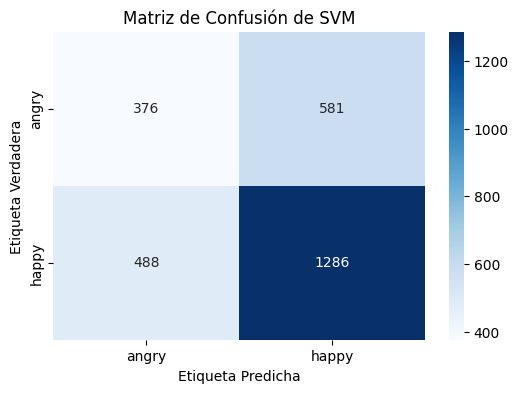

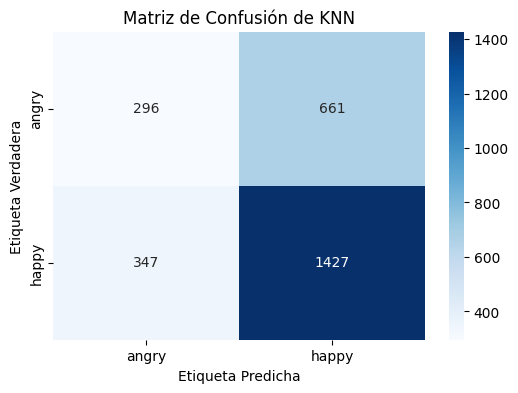

=== Validación Cruzada ===
Precisión de SVM con Validación Cruzada: 0.61 ± 0.01
Precisión de KNN con Validación Cruzada: 0.64 ± 0.01


In [ ]:
# Convertir a arrays de NumPy
train_features = np.array(train_features)
train_labels = np.array(train_labels)
test_features = np.array(test_features)
test_labels = np.array(test_labels)

# Escalado de características
all_features = np.vstack((train_features, test_features))
scaler = StandardScaler()
scaler.fit(all_features)

train_features_scaled = scaler.transform(train_features)
test_features_scaled = scaler.transform(test_features)

# Entrenar y evaluar SVM
svm_classifier = SVC(kernel='linear', probability=True, random_state=42, class_weight='balanced')
svm_classifier.fit(train_features_scaled, train_labels)
svm_predictions = svm_classifier.predict(test_features_scaled)

# Entrenar y evaluar KNN
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_scaled, train_labels)
knn_predictions = knn_classifier.predict(test_features_scaled)

# Evaluación de SVM
print("=== SVM ===")
svm_accuracy = accuracy_score(test_labels, svm_predictions)
print(f"Precisión: {svm_accuracy:.2f}")
svm_conf_matrix = confusion_matrix(test_labels, svm_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, svm_predictions, target_names=['angry', 'happy']))

# Evaluación de KNN
print("=== KNN ===")
knn_accuracy = accuracy_score(test_labels, knn_predictions)
print(f"Precisión: {knn_accuracy:.2f}")
knn_conf_matrix = confusion_matrix(test_labels, knn_predictions)
print("Informe de Clasificación:")
print(classification_report(test_labels, knn_predictions, target_names=['angry', 'happy']))

# Visualización de las Matrices de Confusión
def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

plot_confusion_matrix(svm_conf_matrix, "Matriz de Confusión de SVM")
plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

# Validación Cruzada
print("=== Validación Cruzada ===")
svm_cv_scores = cross_val_score(svm_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de SVM con Validación Cruzada: {svm_cv_scores.mean():.2f} ± {svm_cv_scores.std():.2f}")

knn_cv_scores = cross_val_score(knn_classifier, train_features_scaled, train_labels, cv=5)
print(f"Precisión de KNN con Validación Cruzada: {knn_cv_scores.mean():.2f} ± {knn_cv_scores.std():.2f}")

=== KNN ===
Precisión: 0.58
              precision    recall  f1-score   support

       angry       0.40      0.39      0.39       957
       happy       0.67      0.68      0.68      1774

    accuracy                           0.58      2731
   macro avg       0.54      0.53      0.54      2731
weighted avg       0.58      0.58      0.58      2731



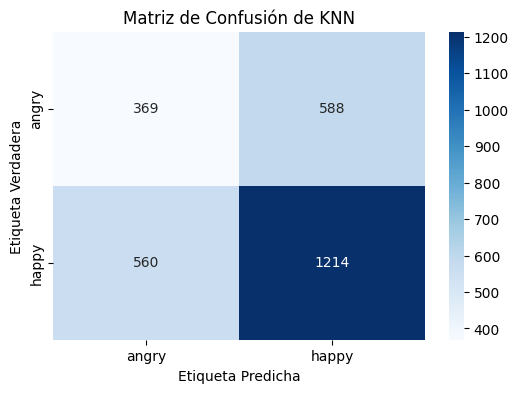

In [ ]:
from sklearn.utils import resample

# Combinar características y etiquetas
train_data = np.column_stack((train_features_scaled, train_labels))

# Separar las clases
angry_data = train_data[train_data[:, -1] == 0]  # Clase 'angry'
happy_data = train_data[train_data[:, -1] == 1]  # Clase 'happy'

# Sobremuestrear la clase 'angry'
angry_upsampled = resample(angry_data,
                            replace=True,     # Permitir el reemplazo
                            n_samples=len(happy_data),    # Igualar el tamaño de la clase 'happy'
                            random_state=42)  # Para reproducibilidad

# Combinar las clases de nuevo
upsampled_train_data = np.vstack((happy_data, angry_upsampled))

# Separar características y etiquetas
train_features_scaled = upsampled_train_data[:, :-1]
train_labels = upsampled_train_data[:, -1]

from sklearn.neighbors import KNeighborsClassifier

# Entrenar KNN
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(train_features_scaled, train_labels)

# Evaluación de KNN
knn_predictions = knn_classifier.predict(test_features_scaled)
print("=== KNN ===")
knn_accuracy = accuracy_score(test_labels, knn_predictions)
print(f"Precisión: {knn_accuracy:.2f}")
print(classification_report(test_labels, knn_predictions, target_names=['angry', 'happy']))

def plot_confusion_matrix(cm, title):
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['angry', 'happy'], yticklabels=['angry', 'happy'])
    plt.ylabel('Etiqueta Verdadera')
    plt.xlabel('Etiqueta Predicha')
    plt.title(title)
    plt.show()

# Matriz de confusión para KNN
knn_conf_matrix = confusion_matrix(test_labels, knn_predictions)
plot_confusion_matrix(knn_conf_matrix, "Matriz de Confusión de KNN")

# Informe adicional con el banalnce en SVM pero no en KNN

In [ ]:
# Informe adicional de precisión, recall y F1-Score
print("=== Métricas Adicionales ===")
# SVM
svm_precision = precision_score(test_labels, svm_predictions, average='binary')
svm_recall = recall_score(test_labels, svm_predictions, average='binary')
svm_f1 = f1_score(test_labels, svm_predictions, average='binary')
print(f"SVM - Precisión: {svm_precision:.2f}, Recall: {svm_recall:.2f}, F1-Score: {svm_f1:.2f}")

# KNN
knn_precision = precision_score(test_labels, knn_predictions, average='binary')
knn_recall = recall_score(test_labels, knn_predictions, average='binary')
knn_f1 = f1_score(test_labels, knn_predictions, average='binary')
print(f"KNN - Precisión: {knn_precision:.2f}, Recall: {knn_recall:.2f}, F1-Score: {knn_f1:.2f}")

# Ajuste de Hiperparámetros
# SVM
svm_param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf', 'poly'],
    'gamma': ['scale', 'auto']
}
svm_grid = GridSearchCV(SVC(probability=True, random_state=42), svm_param_grid, cv=5, scoring='accuracy')
svm_grid.fit(train_features_scaled, train_labels)
print(f"Mejores parámetros para SVM: {svm_grid.best_params_}")
print(f"Mejor precisión de SVM: {svm_grid.best_score_:.2f}")
best_svm = svm_grid.best_estimator_
svm_best_predictions = best_svm.predict(test_features_scaled)
print(f"Precisión del mejor SVM: {accuracy_score(test_labels, svm_best_predictions):.2f}")

# KNN
knn_param_grid = {
    'n_neighbors': list(range(1, 31)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5, scoring='accuracy')
knn_grid.fit(train_features_scaled, train_labels)
print(f"Mejores parámetros para KNN: {knn_grid.best_params_}")
print(f"Mejor precisión de KNN: {knn_grid.best_score_:.2f}")
best_knn = knn_grid.best_estimator_
knn_best_predictions = best_knn.predict(test_features_scaled)
print(f"Precisión del mejor KNN: {accuracy_score(test_labels, knn_best_predictions):.2f}")

=== Métricas Adicionales ===
SVM - Precisión: 0.69, Recall: 0.72, F1-Score: 0.71
KNN - Precisión: 0.68, Recall: 0.80, F1-Score: 0.74
